In [1]:
import pandas as pd

In [2]:
!ls ../dataset_kraken/


family_name_ids.csv  genus_name_ids.csv  species_name_ids.csv
family_seqs.csv      genus_seqs.csv	 species_seqs.csv


In [3]:
species_labels = pd.read_csv("../dataset_kraken/species_name_ids.csv")


In [4]:
species_labels.head()

,species,id
0,Alphafusarivirus rutstroemiae,1
1,Alphafusarivirus macrophominae,2
2,Alphafusarivirus ioaponiae,3
3,Alphafusarivirus auriculariae,4
4,Alphafusarivirus penicilli,5


In [10]:
ictv_master = pd.read_excel("ICTV_Master_Species_List_2025_MSL41.v1.xlsx",sheet_name='MSL')
ictv_renames = pd.read_excel("ICTV_Master_Species_List_2025_MSL41.v1.xlsx",sheet_name='Taxa Renamed or Abolished')

In [11]:
ictv_master.head()

,Sort,Realm,Subrealm,Kingdom,Subkingdom,Phylum,Subphylum,Class,Subclass,Order,...,Family,Subfamily,Genus,Subgenus,Species,ICTV_ID,Genome,Last Change,MSL of Last Change,Proposal for Last Change
0,1,Adnaviria,NaN,Zilligvirae,NaN,Taleaviricota,NaN,Tokiviricetes,NaN,Ligamenvirales,...,Chiyouviridae,NaN,Wargodvirus,NaN,Wargodvirus xiongnu,ICTV202420188,dsDNA,"New,",40,2024.005A.Bathyarchaeia_4newfam.zip
1,2,Adnaviria,NaN,Zilligvirae,NaN,Taleaviricota,NaN,Tokiviricetes,NaN,Ligamenvirales,...,Lipothrixviridae,NaN,Alphalipothrixvirus,NaN,Alphalipothrixvirus beppuense,ICTV201908643,dsDNA,"Renamed,",39,2023.001A.Archaeal_binomials.zip
2,3,Adnaviria,NaN,Zilligvirae,NaN,Taleaviricota,NaN,Tokiviricetes,NaN,Ligamenvirales,...,Lipothrixviridae,NaN,Alphalipothrixvirus,NaN,Alphalipothrixvirus umijigokuense,ICTV201908644,dsDNA,"Renamed,",39,2023.001A.Archaeal_binomials.zip
3,4,Adnaviria,NaN,Zilligvirae,NaN,Taleaviricota,NaN,Tokiviricetes,NaN,Ligamenvirales,...,Lipothrixviridae,NaN,Betalipothrixvirus,NaN,Betalipothrixvirus acidiani,ICTV20094000,dsDNA,"Renamed,",39,2023.001A.Archaeal_binomials.zip
4,5,Adnaviria,NaN,Zilligvirae,NaN,Taleaviricota,NaN,Tokiviricetes,NaN,Ligamenvirales,...,Lipothrixviridae,NaN,Betalipothrixvirus,NaN,Betalipothrixvirus hveragerdiense,ICTV20041365,dsDNA,"Renamed,",39,2023.001A.Archaeal_binomials.zip


In [12]:
ictv_renames.head()

,ICVD_ID,Rank,Change,Old Name,New Name,proposal
0,ICTV201907161,realm,Renamed,Monodnaviria,Floreoviria,2025.002G.Monodnaviria_reorg_4nr.zip
1,ICTV201907168,class,Abolished,Monodnaviria;Sangervirae;Phixviricota;Malgrand...,NaN,2025.043B.Microviricetes_reorg.zip
2,ICTV201907169,order,Abolished,Monodnaviria;Sangervirae;Phixviricota;Malgrand...,NaN,2025.043B.Microviricetes_reorg.zip
3,ICTV19780013,family>class,"Renamed,Promoted",Monodnaviria;Sangervirae;Phixviricota;Malgrand...,Volvereviria;Sangervirae;Phixviricota;Microvir...,2025.043B.Microviricetes_reorg.zip
4,ICTV202419628,family,Renamed,Riboviria;Orthornavirae;Orpoviricetes;Bormycov...,Riboviria;Orthornavirae;Orpoviricetes;Bormycov...,2025.004F.Deltanormycoviridae_rename.zip


In [19]:
def build_ictv_rename_map(df_renames):
    """
    Varre a tabela de renames do ICTV e isola o mapeamento de string
    de nomes antigos de espécies para os nomes oficiais atualizados.
    """
    rename_map = {}
    
    # Filtra apenas linhas que possuem modificações do tipo 'Renamed'
    df_filtered = df_renames[df_renames['Change'].str.contains('Renamed', na=False, case=False)]
    
    for _, row in df_filtered.iterrows():
        old_full = str(row['Old Name'])
        new_full = str(row['New Name'])
        
        # Como o ICTV salva a linhagem completa (Order;Family;Genus;Species)
        # pegamos o último elemento de cada string limpa
        old_species = old_full.split(';')[-1].strip().lower()
        new_species = new_full.split(';')[-1].strip().lower()
        
        if old_species and new_species and old_species != new_species:
            rename_map[old_species] = new_species
            
    print(f"🔄 Dicionário de reanotações do ICTV construído: {len(rename_map)} regras mapeadas.")
    return rename_map

# Executa a extração
mapa_atualizacoes = build_ictv_rename_map(ictv_renames)


🔄 Dicionário de reanotações do ICTV construído: 162 regras mapeadas.


In [21]:
import pandas as pd
from rapidfuzz import process, fuzz

# ==============================================================================
# 1. PADRONIZAÇÃO E MAPEAMENTO INICIAL (Mantendo sua lógica base)
# ==============================================================================
species_labels['species_clean'] = species_labels['species'].str.strip().str.lower()
species_labels['species_ictv'] = species_labels['species_clean'].map(mapa_atualizacoes).fillna(species_labels['species_clean'])

# Criamos uma lista limpa das espécies oficiais do ICTV para a busca por similaridade
ictv_master_list = ictv_master['Species'].str.strip().dropna().unique()
ictv_master_set = set(s.lower() for s in ictv_master_list)

# Criamos um dicionário de mapeamento direto (lowercase -> formato original do ICTV)
# Isso nos ajudará a recuperar o nome com a grafia correta (maiúsculas/minúsculas) depois
ictv_original_case_map = {s.lower(): s for s in ictv_master_list}

# ==============================================================================
# 2. NOVA LOGICA DE BUSCA EXPANDIDA (Com Fuzzy Matching)
# ==============================================================================
print("🧠 Iniciando processamento adaptativo de taxonomia...")

def verificar_status_ictv_expandido(row):
    nome_alvo = row['species_ictv']
    nome_original = row['species_clean']
    
    # 🟢 CASO 1: Match Perfeito Direto
    if nome_alvo in ictv_master_set:
        return 'Homologado (ICTV Direct)', nome_alvo
    
    # 🟢 CASO 2: Match Perfeito após a tabela de Renames
    if nome_original != nome_alvo and nome_alvo in ictv_master_set:
        return 'Atualizado via Renames (ICTV)', nome_alvo
        
    # 🟡 CASO 3: Busca por Similaridade de String (Fuzzy Matching)
    # process.extractOne busca a string mais próxima dentro da lista do ICTV
    # scorer=fuzz.WRatio lida muito bem com inversões de palavras ou pequenas diferenças
    match_fuzzy = process.extractOne(nome_alvo, ictv_master_set, scorer=fuzz.WRatio, score_cutoff=90.0)
    
    if match_fuzzy:
        nome_encontrado_fuzzy, score, _ = match_fuzzy
        # Retorna o status com o score para auditoria e o nome corrigido que foi achado no ICTV
        return f'Homologado via Similaridade (Score: {int(score)}%)', nome_encontrado_fuzzy
        
    # 🔴 CASO 4: Se falhar em tudo, cai no Fallback do NCBI
    return 'Não Encontrado no ICTV (NCBI Fallback)', nome_alvo

# Aplicando a função linha por linha no DataFrame
print("⏳ Executando casamento de strings de alta performance...")
resultados_busca = species_labels.apply(verificar_status_ictv_expandido, axis=1)

# Desempacota os resultados em duas colunas novas
species_labels['ictv_status'] = [res[0] for res in list(resultados_busca)]
species_labels['species_validated_name'] = [ictv_original_case_map.get(res[1], res[1]) for res in list(resultados_busca)]

# ==============================================================================
# 3. RELATÓRIO DE IMPACTO PARA A SUA DEFESA (UFRGS)
# ==============================================================================
print("\n📊 NOVO Perfil do Dataset em relação à autoridade do ICTV:")
perfil = species_labels['ictv_status'].value_counts()
print(perfil)

# Calcula o ganho real de dados homologados
total_homologado = perfil.filter(like='Homologado').sum() + perfil.filter(like='Atualizado').sum()
pct_ganho = (total_homologado / len(species_labels)) * 100
print(f"\n✅ Total de dados blindados e chancelados pelo ICTV: {total_homologado:,} de {len(species_labels):,} ({pct_ganho:.2f}%)")

🧠 Iniciando processamento adaptativo de taxonomia...
⏳ Executando casamento de strings de alta performance...

📊 NOVO Perfil do Dataset em relação à autoridade do ICTV:
ictv_status
Homologado (ICTV Direct)                    7746
Não Encontrado no ICTV (NCBI Fallback)      5723
Homologado via Similaridade (Score: 90%)     131
Homologado via Similaridade (Score: 92%)      24
Homologado via Similaridade (Score: 91%)      15
Homologado via Similaridade (Score: 93%)      14
Homologado via Similaridade (Score: 95%)      12
Homologado via Similaridade (Score: 94%)       8
Homologado via Similaridade (Score: 96%)       5
Homologado via Similaridade (Score: 97%)       4
Homologado via Similaridade (Score: 98%)       1
Name: count, dtype: int64

✅ Total de dados blindados e chancelados pelo ICTV: 7,960 de 13,683 (58.17%)


In [22]:
species_labels.head()

,species,id,species_clean,species_ictv,ictv_status,species_validated_name
0,Alphafusarivirus rutstroemiae,1,alphafusarivirus rutstroemiae,alphafusarivirus rutstroemiae,Homologado (ICTV Direct),Alphafusarivirus rutstroemiae
1,Alphafusarivirus macrophominae,2,alphafusarivirus macrophominae,alphafusarivirus macrophominae,Homologado (ICTV Direct),Alphafusarivirus macrophominae
2,Alphafusarivirus ioaponiae,3,alphafusarivirus ioaponiae,alphafusarivirus ioaponiae,Homologado (ICTV Direct),Alphafusarivirus ioaponiae
3,Alphafusarivirus auriculariae,4,alphafusarivirus auriculariae,alphafusarivirus auriculariae,Homologado (ICTV Direct),Alphafusarivirus auriculariae
4,Alphafusarivirus penicilli,5,alphafusarivirus penicilli,alphafusarivirus penicilli,Homologado (ICTV Direct),Alphafusarivirus penicilli


In [23]:
import os
import pandas as pd

def resolve_local_ictv_taxonomy(df, ictv_master, species_col='species_ictv'):
    """
    Realiza o mapeamento completo e instantâneo das colunas taxonômicas do ICTV
    utilizando lookups de dicionários em memória.
    """
    print("🧠 Construindo indexadores de alta performance para o ICTV...")
    
    # Lista de colunas oficiais requisitadas do ICTV
    colunas_tax = [
        "Realm", "Subrealm", "Kingdom", "Subkingdom", "Phylum", "Subphylum", 
        "Class", "Subclass", "Order", "Suborder", "Family", "Subfamily", "Genus", "Subgenus"
    ]
    
    # Padroniza o ICTV Master para casamento de strings limpo
    ictv_df = ictv_master.copy()
    ictv_df['species_match'] = ictv_df['Species'].str.strip().str.lower()
    
    # Remove duplicatas históricas para garantir chave primária única por espécie
    ictv_df = ictv_df.drop_duplicates(subset=['species_match'])
    
    # Cria um mega dicionário onde a chave é a espécie e o valor é a série com toda a linhagem
    # orient='index' transforma o nome da espécie na chave do dicionário de busca rápida
    dict_lookup = ictv_df.set_index('species_match')[colunas_tax].to_dict(orient='index')
    
    df_result = df.copy()
    df_result['species_lookup_key'] = df_result[species_col].str.strip().str.lower()
    
    print("⚡ Mapeando árvore filogenética local...")
    
    # Inicializa todas as colunas vazias no DataFrame de destino
    for col in colunas_tax:
        df_result[col] = None
    df_result['taxonomy_source'] = "NCBI Fallback"  # Default global antes do mapeamento
    
    # Executa o casamento de dados em lote via memória
    records = []
    for row in df_result.itertuples():
        key = row.species_lookup_key
        
        if key in dict_lookup:
            # Recupera toda a árvore estruturada do ICTV instantaneamente
            tax_data = dict_lookup[key]
            tax_data['taxonomy_source'] = "ICTV Master"
            records.append(tax_data)
        else:
            # Mantém vazio para o preenchimento posterior do NCBI
            empty_record = {col: None for col in colunas_tax}
            empty_record['taxonomy_source'] = "NCBI Fallback"
            records.append(empty_record)
            
    # Consolida as novas colunas mapeadas de volta ao DataFrame principal
    df_tax_mapped = pd.DataFrame(records, index=df_result.index)
    for col in colunas_tax + ['taxonomy_source']:
        df_result[col] = df_tax_mapped[col]
        
    df_result = df_result.drop(columns=['species_lookup_key'])
    
    # Relatório operacional para conferência
    perfil = df_result['taxonomy_source'].value_counts()
    print(f"   -> Mapeados localmente via ICTV: {perfil.get('ICTV Master', 0):,}")
    print(f"   -> Encaminhados para o Fallback NCBI: {perfil.get('NCBI Fallback', 0):,}")
    
    return df_result

In [24]:
import pandas as pd
from Bio import Entrez
import time
import re
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed

def fetch_ncbi_taxonomy_parallel(df, email, api_key=None, species_col='species_ictv', max_retries=5, max_workers=None):
    """
    Buscador paralelo adaptado para preencher de forma granular as colunas de linhagem
    completas do NCBI apenas para amostras não encontradas no ICTV.
    """
    Entrez.email = email
    if api_key:
        Entrez.api_key = api_key
    
    if max_workers is None:
        max_workers = 10 if api_key else 3

    def get_single_species(index, species):
        if re.match(r'^\d{4}$|^[A-Z]{1,3}$|^\d+$', str(species).strip()):
            return index, None, "Invalid Name"

        for attempt in range(max_retries):
            try:
                search_handle = Entrez.esearch(db="taxonomy", term=species)
                search_record = Entrez.read(search_handle)
                search_handle.close()
                
                if not search_record["IdList"]:
                    return index, None, "Not Found"
                
                tax_id = search_record["IdList"][0]
                fetch_handle = Entrez.efetch(db="taxonomy", id=tax_id, retmode="xml")
                fetch_record = Entrez.read(fetch_handle)
                fetch_handle.close()
                
                lineage_nodes = fetch_record[0].get("LineageEx", [])
                full_path = " / ".join([n.get("ScientificName") for n in lineage_nodes])
                
                # Mapeamento dinâmico inteligente das posições do NCBI para a estrutura ICTV
                # O NCBI usa strings de rank comuns. Nós normalizamos para as colunas do seu df
                rank_mapping = {
                    'realm': 'Realm', 'kingdom': 'Kingdom', 'phylum': 'Phylum',
                    'class': 'Class', 'order': 'Order', 'family': 'Family', 'genus': 'Genus'
                }
                
                found_tax = {v: None for v in rank_mapping.values()}
                for node in lineage_nodes:
                    rank = node.get("Rank")
                    if rank in rank_mapping:
                        found_tax[rank_mapping[rank]] = node.get("ScientificName")
                        
                return index, found_tax, full_path
                
            except Exception as e:
                if attempt < max_retries - 1:
                    time.sleep((attempt + 1) * 2)
                    continue
                return index, None, f"Fatal: {str(e)}"

    results_map = {}
    species_list = list(enumerate(df[species_col]))

    print(f"🚀 Disparando requisições assíncronas para {len(df)} alvos no NCBI...")
    
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        futures = {executor.submit(get_single_species, i, name): i for i, name in species_list}
        
        for future in tqdm(as_completed(futures), total=len(futures), desc="NCBI Fallback API"):
            idx, tax_dict, path = future.result()
            results_map[idx] = (tax_dict, path)
            time.sleep(1 / max_workers)

    # Remonta os dados preservando o índice do DataFrame de Fallback
    df_result = df.copy()
    full_paths = []
    
    # Colunas de interesse
    colunas_preenchimento = ["Realm", "Kingdom", "Phylum", "Class", "Order", "Family", "Genus"]
    
    # Dicionários temporários para armazenar as atualizações por coluna
    colunas_dados = {col: [] for col in colunas_preenchimento}

    for i in range(len(df)):
        tax_dict, path = results_map[i]
        full_paths.append(path)
        
        for col in colunas_preenchimento:
            val = tax_dict.get(col) if tax_dict else None
            colunas_dados[col].append(val)

    # Despeja as colunas preenchidas pelo NCBI
    for col in colunas_preenchimento:
        df_result[col] = colunas_dados[col]
    df_result['full_lineage'] = full_paths

    return df_result


In [26]:
# ==============================================================================
# PASSO 1: Processamento em Memória via ICTV (Roda em menos de 1 segundo)
# ==============================================================================
df_pre_mapped = resolve_local_ictv_taxonomy(
    df=species_labels, 
    ictv_master=ictv_master, 
    species_col='species_ictv'
)

# ==============================================================================
# PASSO 2: Separação Cirúrgica dos Datasets
# ==============================================================================
df_ictv_pronto = df_pre_mapped[df_pre_mapped['taxonomy_source'] == "ICTV Master"].copy()
df_necessita_ncbi = df_pre_mapped[df_pre_mapped['taxonomy_source'] == "NCBI Fallback"].copy()

# 🛠️ CORREÇÃO: 'Species' alterado para 'species' (ou 'species_ictv') para casar com seu DataFrame
colunas_lineage_ictv = ["Realm", "Kingdom", "Phylum", "Class", "Order", "Family", "Genus", "species_ictv"]

# Criar a string de linhagem de forma robusta combinando as colunas preenchidas com ' / '
# Usamos .ffill(axis=1) para garantir compatibilidade entre versões do Pandas
df_ictv_pronto['full_lineage'] = df_ictv_pronto[colunas_lineage_ictv].ffill(axis=1).apply(
    lambda row: " / ".join([str(val) for val in row if pd.notna(val)]), axis=1
)

# ==============================================================================
# PASSO 3: Execução de Rede Otimizada (Roda APENAS para os não encontrados)
# ==============================================================================
if len(df_necessita_ncbi) > 0:
    # Reseta o index temporariamente para garantir o alinhamento do loop interno da ThreadPool
    df_ncbi_idx_reset = df_necessita_ncbi.reset_index(drop=True)
    
    df_ncbi_resolvido = fetch_ncbi_taxonomy_parallel(
        df=df_ncbi_idx_reset,
        email="matheuslimaaa13@gmail.com",
        api_key="602c9bd77a872b",
        species_col='species_ictv'
    )
    
    # Restaura o índice original do Kraken para a concatenação perfeita
    df_ncbi_resolvido.index = df_necessita_ncbi.index
else:
    df_ncbi_resolvido = pd.DataFrame()

# ==============================================================================
# PASSO 4: Reconstrução e Salvamento do Dataset Final Auditado
# ==============================================================================
print("\n🔄 Consolidando bases de dados híbridas...")
df_final_completo = pd.concat([df_ictv_pronto, df_ncbi_resolvido]).sort_index()

# Salva no disco no diretório padrão de Parquet do seu projeto
os.makedirs("./data_taxonomy_parquet", exist_ok=True)
df_final_completo.to_parquet("./data_taxonomy_parquet/main_taxonomy_hybrid_ictv_ncbi.parquet", index=False)

print("🎯 Pipeline executado com sucesso!")
print(df_final_completo['taxonomy_source'].value_counts())

🧠 Construindo indexadores de alta performance para o ICTV...
⚡ Mapeando árvore filogenética local...
   -> Mapeados localmente via ICTV: 7,746
   -> Encaminhados para o Fallback NCBI: 5,937
🚀 Disparando requisições assíncronas para 5937 alvos no NCBI...


NCBI Fallback API: 100%|██████████| 5937/5937 [3:33:37<00:00,  2.16s/it]  



🔄 Consolidando bases de dados híbridas...
🎯 Pipeline executado com sucesso!
taxonomy_source
ICTV Master      7746
NCBI Fallback    5937
Name: count, dtype: int64


In [29]:
df_final_completo.head()

,species,id,species_clean,species_ictv,ictv_status,species_validated_name,Realm,Subrealm,Kingdom,Subkingdom,...,Class,Subclass,Order,Suborder,Family,Subfamily,Genus,Subgenus,taxonomy_source,full_lineage
0,Alphafusarivirus rutstroemiae,1,alphafusarivirus rutstroemiae,alphafusarivirus rutstroemiae,Homologado (ICTV Direct),Alphafusarivirus rutstroemiae,Riboviria,NaN,Orthornavirae,NaN,...,Stelpaviricetes,NaN,Hypofuvirales,NaN,Fusariviridae,NaN,Alphafusarivirus,NaN,ICTV Master,Riboviria / Orthornavirae / Pisuviricota / Ste...
1,Alphafusarivirus macrophominae,2,alphafusarivirus macrophominae,alphafusarivirus macrophominae,Homologado (ICTV Direct),Alphafusarivirus macrophominae,Riboviria,NaN,Orthornavirae,NaN,...,Stelpaviricetes,NaN,Hypofuvirales,NaN,Fusariviridae,NaN,Alphafusarivirus,NaN,ICTV Master,Riboviria / Orthornavirae / Pisuviricota / Ste...
2,Alphafusarivirus ioaponiae,3,alphafusarivirus ioaponiae,alphafusarivirus ioaponiae,Homologado (ICTV Direct),Alphafusarivirus ioaponiae,Riboviria,NaN,Orthornavirae,NaN,...,Stelpaviricetes,NaN,Hypofuvirales,NaN,Fusariviridae,NaN,Alphafusarivirus,NaN,ICTV Master,Riboviria / Orthornavirae / Pisuviricota / Ste...
3,Alphafusarivirus auriculariae,4,alphafusarivirus auriculariae,alphafusarivirus auriculariae,Homologado (ICTV Direct),Alphafusarivirus auriculariae,Riboviria,NaN,Orthornavirae,NaN,...,Stelpaviricetes,NaN,Hypofuvirales,NaN,Fusariviridae,NaN,Alphafusarivirus,NaN,ICTV Master,Riboviria / Orthornavirae / Pisuviricota / Ste...
4,Alphafusarivirus penicilli,5,alphafusarivirus penicilli,alphafusarivirus penicilli,Homologado (ICTV Direct),Alphafusarivirus penicilli,Riboviria,NaN,Orthornavirae,NaN,...,Stelpaviricetes,NaN,Hypofuvirales,NaN,Fusariviridae,NaN,Alphafusarivirus,NaN,ICTV Master,Riboviria / Orthornavirae / Pisuviricota / Ste...


In [30]:
# 1. Ajusta para o nome do DataFrame consolidado do novo pipeline
df_final = df_final_completo

# 2. Filtra linhas onde qualquer um dos níveis taxonômicos principais ficou vazio (None/NaN)
# Usamos as novas colunas textuais geradas pelo casamento ICTV/NCBI
missing_taxonomy_df = df_final[
    df_final['Order'].isna() | 
    df_final['Family'].isna() | 
    df_final['Genus'].isna()
]

# 3. Exibe o relatório de integridade dos dados para a banca
print("=" * 60)
print("📊 RELATÓRIO DE INTEGRIDADE DA TAXONOMIA HÍBRIDA")
print("=" * 60)
print(f"Total de linhas com dados ausentes/órfãos: {len(missing_taxonomy_df)} de {len(df_final)}")

if len(missing_taxonomy_df) > 0:
    print("\n⚠️ Distribuição da origem dos dados falhos:")
    print(missing_taxonomy_df['taxonomy_source'].value_counts())
    
    print("\n📋 Amostra das linhas com inconsistência:")
    # Exibe colunas chaves para auditoria visual rápida
    colunas_auditoria = ['species', 'species_ictv', 'taxonomy_source', 'Order', 'Family', 'Genus']
    print(missing_taxonomy_df[colunas_auditoria].head(10))
else:
    print("\n✅ Perfeito! 100% das classes possuem encadeamento filogenético completo (Order -> Family -> Genus).")
print("=" * 60)

📊 RELATÓRIO DE INTEGRIDADE DA TAXONOMIA HÍBRIDA
Total de linhas com dados ausentes/órfãos: 9155 de 13683

⚠️ Distribuição da origem dos dados falhos:
taxonomy_source
NCBI Fallback    5937
ICTV Master      3218
Name: count, dtype: int64

📋 Amostra das linhas com inconsistência:
                               species                        species_ictv  \
34     Nigrospora oryzae fusarivirus 1     nigrospora oryzae fusarivirus 1   
35  Sodiomyces alkalinus fusarivirus 1  sodiomyces alkalinus fusarivirus 1   
36       Heterobasidion partitivirus P       heterobasidion partitivirus p   
37        Atkinsonella hypoxylon virus        atkinsonella hypoxylon virus   
38       Heterobasidion partitivirus 8       heterobasidion partitivirus 8   
39      Crimson clover cryptic virus 2      crimson clover cryptic virus 2   
40     Ceratocystis resinifera virus 1     ceratocystis resinifera virus 1   
41         Hop trefoil cryptic virus 2         hop trefoil cryptic virus 2   
42              Cann

In [34]:
print("Species with missing taxonomic ranks:", missing_taxonomy_df['species'].tolist())

Species with missing taxonomic ranks: ['Nigrospora oryzae fusarivirus 1', 'Sodiomyces alkalinus fusarivirus 1', 'Heterobasidion partitivirus P', 'Atkinsonella hypoxylon virus', 'Heterobasidion partitivirus 8', 'Crimson clover cryptic virus 2', 'Ceratocystis resinifera virus 1', 'Hop trefoil cryptic virus 2', 'Cannabis cryptic virus', 'Heterobasidion partitivirus 7', 'Rhizoctonia solani virus 717', 'Fusarium poae virus 1', 'Rosellinia necatrix partitivirus 6', 'Heterobasidion partitivirus 2', 'Primula malacoides virus 1', 'Rosellinia necatrix virus 1', 'Pleurotus ostreatus virus 1', 'Dill cryptic virus 2', 'Red clover cryptic virus 2', 'White clover cryptic virus 2', 'Verticillium dahliae partitivirus 1', 'Spinach cryptic virus 1', 'Rhizoctonia solani dsRNA virus 2', 'Dill cryptic virus 1', 'Discula destructiva virus 1', 'Ophiostoma partitivirus 1', 'Discula destructiva virus 2', 'Aspergillus ochraceous virus', 'Pythium nunn virus 1', 'Fusarium solani virus 1', 'Gremmeniella abietina RN

In [35]:
import pandas as pd
import numpy as np

def sanear_inconsistencias_taxonomicas(df_final):
    """
    Higieniza o DataFrame híbrido substituindo valores None/NaN por categorias
    operacionais explícitas (Unclassified), impedindo quebras no treinamento e nas métricas.
    """
    df_clean = df_final.copy()
    
    print("🧹 Iniciando saneamento de ranks ausentes...")
    
    # Lista de colunas na ordem hierárquica descendente que você está usando
    hierarchy = ["Realm", "Kingdom", "Phylum", "Class", "Order", "Family", "Genus"]
    
    # 🟢 PASSO 1: Tratamento de strings nulas e limpezas de NaN
    for col in hierarchy:
        df_clean[col] = df_clean[col].astype(str).str.strip()
        # Converte variações de strings vazias ou falhas para o NaN padrão do numpy
        df_clean[col] = df_clean[col].replace(['None', 'nan', 'NaN', '', 'ERROR'], np.nan)
    
    # 🟢 PASSO 2: Imputação Hierárquica Progressiva (Top-Down Fallback)
    # Se o nível superior existe mas o inferior é nulo, preenchemos com "Unclassified [Nível Superior]"
    # Caso o nível superior também seja nulo, buscamos o imediatamente acima até o limite superior.
    
    # Inicializa o primeiro nível (Realm) caso ele seja completamente órfão
    df_clean['Realm'] = df_clean['Realm'].fillna("Unclassified Riboviria") # Como a maioria esmagadora de vírus de RNA e fagos caem aqui
    
    for i in range(1, len(hierarchy)):
        current_rank = hierarchy[i]
        parent_rank = hierarchy[i-1]
        
        # Cria o rótulo dinâmico baseado no nó pai
        label_fallback = "Unclassified " + df_clean[parent_rank].astype(str)
        
        # Substitui os NaNs da coluna atual pelo rótulo descritivo do pai
        df_clean[current_rank] = df_clean[current_rank].fillna(label_fallback)
        
    # Limpeza final de strings redundantes como "Unclassified Unclassified..."
    for col in hierarchy:
        df_clean[col] = df_clean[col].apply(lambda x: re.sub(r'(Unclassified\s+)+', 'Unclassified ', str(x)))
    
    # 🟢 PASSO 3: Validação pós-higienização
    total_invalidos = df_clean[hierarchy].isna().any(axis=1).sum()
    print(f"✅ Saneamento concluído. Ranks nulos residuais: {total_invalidos}")
    
    # Exibe a distribuição do perfil de Gêneros atualizado para auditoria
    print("\n📝 Amostra do novo encadeamento estruturado (Top 5 linhas corrigidas):")
    colunas_conferencia = ['species', 'taxonomy_source', 'Order', 'Family', 'Genus']
    print(df_clean[colunas_conferencia].loc[df_final['Genus'].isna()].head(5))
    
    # Salva a versão final blindada pronta para o fluxo de Deep Learning / Kraken
    df_clean.to_parquet("./main_taxonomy_hybrid_CLEANSED.parquet", index=False)
    print("\n💾 Dataset final higienizado exportado com sucesso!")
    
    return df_clean

# Executa o saneamento no seu DataFrame consolidado
df_final_saneado = sanear_inconsistencias_taxonomicas(df_final_completo)

🧹 Iniciando saneamento de ranks ausentes...
✅ Saneamento concluído. Ranks nulos residuais: 0

📝 Amostra do novo encadeamento estruturado (Top 5 linhas corrigidas):
                               species taxonomy_source  \
34     Nigrospora oryzae fusarivirus 1   NCBI Fallback   
35  Sodiomyces alkalinus fusarivirus 1   NCBI Fallback   
36       Heterobasidion partitivirus P   NCBI Fallback   
37        Atkinsonella hypoxylon virus   NCBI Fallback   
38       Heterobasidion partitivirus 8   NCBI Fallback   

                     Order                  Family                   Genus  
34  Unclassified Riboviria  Unclassified Riboviria  Unclassified Riboviria  
35  Unclassified Riboviria  Unclassified Riboviria  Unclassified Riboviria  
36  Unclassified Riboviria  Unclassified Riboviria  Unclassified Riboviria  
37  Unclassified Riboviria  Unclassified Riboviria  Unclassified Riboviria  
38  Unclassified Riboviria  Unclassified Riboviria  Unclassified Riboviria  

💾 Dataset final higieniz

In [17]:
!pwd

/home/mlima/workspace/cnn_kraken


In [5]:
df_final_saneado=pd.read_parquet("./main_taxonomy_hybrid_CLEANSED.parquet")
df_final_saneado.head()

,species,id,species_clean,species_ictv,ictv_status,species_validated_name,Realm,Subrealm,Kingdom,Subkingdom,...,Class,Subclass,Order,Suborder,Family,Subfamily,Genus,Subgenus,taxonomy_source,full_lineage
0,Alphafusarivirus rutstroemiae,1,alphafusarivirus rutstroemiae,alphafusarivirus rutstroemiae,Homologado (ICTV Direct),Alphafusarivirus rutstroemiae,Riboviria,NaN,Orthornavirae,NaN,...,Stelpaviricetes,NaN,Hypofuvirales,None,Fusariviridae,None,Alphafusarivirus,None,ICTV Master,Riboviria / Orthornavirae / Pisuviricota / Ste...
1,Alphafusarivirus macrophominae,2,alphafusarivirus macrophominae,alphafusarivirus macrophominae,Homologado (ICTV Direct),Alphafusarivirus macrophominae,Riboviria,NaN,Orthornavirae,NaN,...,Stelpaviricetes,NaN,Hypofuvirales,None,Fusariviridae,None,Alphafusarivirus,None,ICTV Master,Riboviria / Orthornavirae / Pisuviricota / Ste...
2,Alphafusarivirus ioaponiae,3,alphafusarivirus ioaponiae,alphafusarivirus ioaponiae,Homologado (ICTV Direct),Alphafusarivirus ioaponiae,Riboviria,NaN,Orthornavirae,NaN,...,Stelpaviricetes,NaN,Hypofuvirales,None,Fusariviridae,None,Alphafusarivirus,None,ICTV Master,Riboviria / Orthornavirae / Pisuviricota / Ste...
3,Alphafusarivirus auriculariae,4,alphafusarivirus auriculariae,alphafusarivirus auriculariae,Homologado (ICTV Direct),Alphafusarivirus auriculariae,Riboviria,NaN,Orthornavirae,NaN,...,Stelpaviricetes,NaN,Hypofuvirales,None,Fusariviridae,None,Alphafusarivirus,None,ICTV Master,Riboviria / Orthornavirae / Pisuviricota / Ste...
4,Alphafusarivirus penicilli,5,alphafusarivirus penicilli,alphafusarivirus penicilli,Homologado (ICTV Direct),Alphafusarivirus penicilli,Riboviria,NaN,Orthornavirae,NaN,...,Stelpaviricetes,NaN,Hypofuvirales,None,Fusariviridae,None,Alphafusarivirus,None,ICTV Master,Riboviria / Orthornavirae / Pisuviricota / Ste...


📊 RELATÓRIO ESTATÍSTICO DE CARDINALIDADE TAXONÔMICA HÍBRIDA
Nível      | Total Real   | Unclassified  | Classes Únicas  | % Sinal Real
----------------------------------------------------------------------
Order      | 4583         | 9100          | 68              | 33.49       %
Family     | 5828         | 7855          | 220             | 42.59       %
Genus      | 7746         | 5937          | 2320            | 56.61       %
Species    | 13683        | 0             | 13630           | 100.00      %
🧬 Volume amostral total do ecossistema de treino: 13,683 leituras.

🎯 Divisão de Autoridade de Fontes:
taxonomy_source
ICTV Master      7746
NCBI Fallback    5937
Name: count, dtype: int64


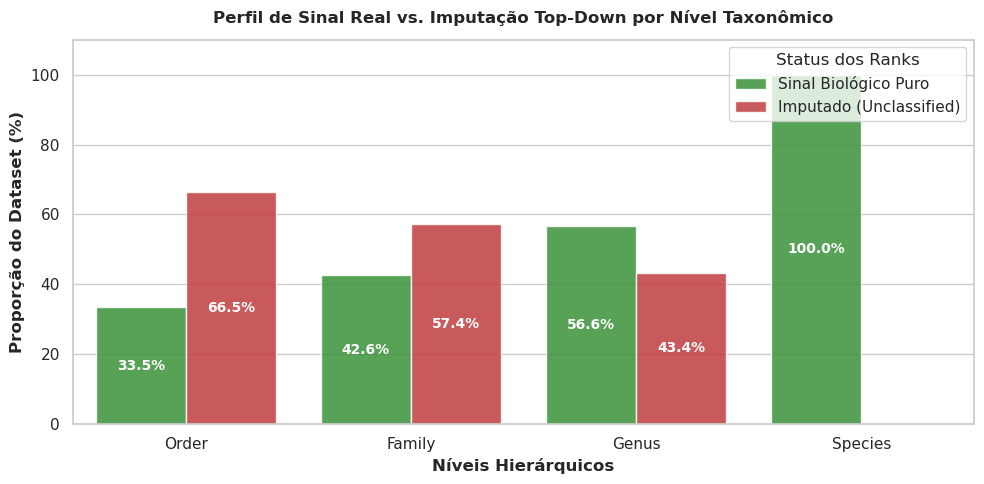

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def print_hybrid_taxonomy_stats(df):
    """
    Calcula e exibe métricas detalhadas de cobertura e cardinalidade para o
    novo DataFrame híbrido (ICTV + NCBI) após o saneamento top-down.
    """
    # 1. Mapeamento para as novas colunas textuais geradas no pipeline
    levels = {
        'Order': 'Order',
        'Family': 'Family',
        'Genus': 'Genus',
        'Species': 'species_validated_name'
    }
    
    print("=" * 70)
    print("📊 RELATÓRIO ESTATÍSTICO DE CARDINALIDADE TAXONÔMICA HÍBRIDA")
    print("=" * 70)
    print(f"{'Nível':<10} | {'Total Real':<12} | {'Unclassified':<13} | {'Classes Únicas':<15} | {'% Sinal Real':<12}")
    print("-" * 70)
    
    total_rows = len(df)
    plot_data = []
    
    for label, col in levels.items():
        # Como o saneamento converteu None para strings descritivos, buscamos a tag 'Unclassified'
        is_unclassified = df[col].astype(str).str.contains('Unclassified', na=False, case=False)
        
        unclassified_count = is_unclassified.sum()
        valid_real_count = total_rows - unclassified_count
        
        # Classes únicas reais (desconsiderando as ramificações artificiais de Unclassified no cálculo de cardinalidade pura)
        unique_classes = df[~is_unclassified][col].nunique()
        
        # Porcentagem de sinal biológico puro (não imputado) disponível para aquele nível
        real_signal_coverage = (valid_real_count / total_rows) * 100
        
        print(f"{label:<10} | {valid_real_count:<12} | {unclassified_count:<13} | {unique_classes:<15} | {real_signal_coverage:<12.2f}%")
        
        # Guarda metadados para o gráfico de diagnóstico
        plot_data.append({'Nível': label, 'Porcentagem': real_signal_coverage, 'Tipo': 'Sinal Biológico Puro'})
        plot_data.append({'Nível': label, 'Porcentagem': 100 - real_signal_coverage, 'Tipo': 'Imputado (Unclassified)'})

    print("=" * 70)
    print(f"🧬 Volume amostral total do ecossistema de treino: {total_rows:,} leituras.")
    if 'taxonomy_source' in df.columns:
        print("\n🎯 Divisão de Autoridade de Fontes:")
        print(df['taxonomy_source'].value_counts())
    print("=" * 70)

    # ==============================================================================
    # 📊 GERADOR DE GRÁFICO AUTOMÁTICO (Pronto para os Slides da Defesa)
    # ==============================================================================
    df_plot = pd.DataFrame(plot_data)
    
    plt.figure(figsize=(10, 5))
    sns.set_theme(style="whitegrid")
    
    # Gráfico de barras empilhadas para mostrar o perfil de preenchimento
    ax = sns.barplot(
        data=df_plot, x='Nível', y='Porcentagem', hue='Tipo', 
        palette=['#2ca02c', '#d62728'], alpha=0.85
    )
    
    # Adiciona as tags de porcentagem nas barras para facilitar a leitura da banca
    for p in ax.patches:
        height = p.get_height()
        if height > 4.0: # Só plota texto se a barra tiver um tamanho mínimo legível
            ax.annotate(f'{height:.1f}%',
                        (p.get_x() + p.get_width() / 2., p.get_y() + height / 2.),
                        ha='center', va='center', fontsize=10, color='white', weight='bold')

    plt.title('Perfil de Sinal Real vs. Imputação Top-Down por Nível Taxonômico', fontweight='bold', fontsize=12, pad=12)
    plt.ylabel('Proporção do Dataset (%)', fontweight='bold')
    plt.xlabel('Níveis Hierárquicos', fontweight='bold')
    plt.ylim(0, 110)
    plt.legend(title="Status dos Ranks", loc='upper right')
    plt.tight_layout()
    
    # Salva na pasta de resultados padrão do seu projeto
    import os
    os.makedirs("results_plots", exist_ok=True)
    plt.savefig("results_plots/hybrid_taxonomy_coverage_profile.png", dpi=300, bbox_inches='tight')
    plt.show()

# --- Execução ---
print_hybrid_taxonomy_stats(df_final_saneado)

💾 Gráfico de duplo eixo exportado com sucesso em: results_plots/hybrid_taxonomy_dual_axis_profile.png


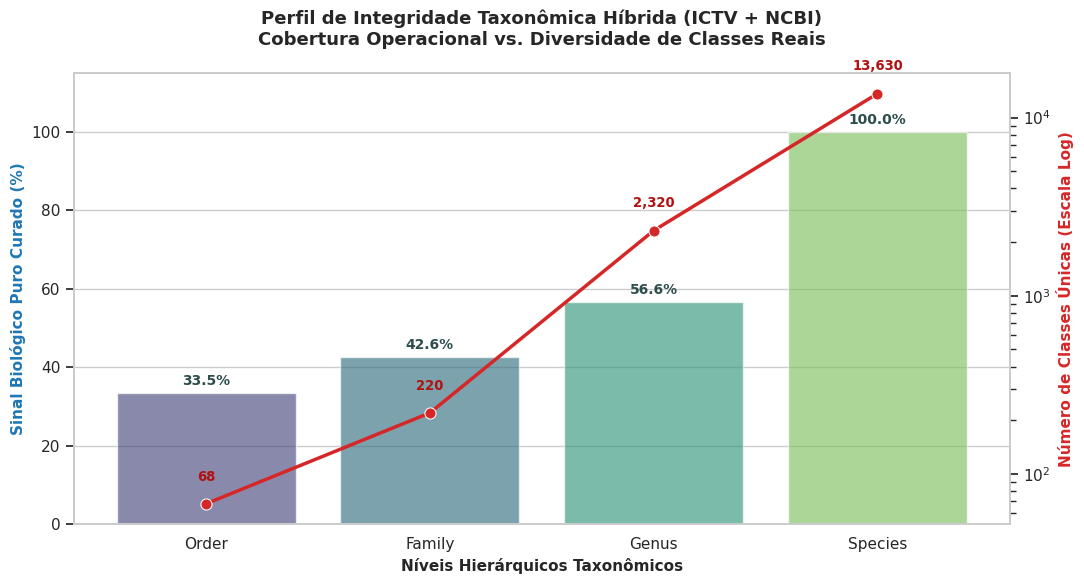

In [7]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_hybrid_taxonomy_stats(df):
    """
    Gera um gráfico de duplo eixo Y comparando a Cobertura de Sinal Real 
    (barras, eixo esquerdo) com a Cardinalidade de Classes Únicas Reis
    (linha em escala logarítmica, eixo direito).
    """
    # 1. Mapeamento para as novas colunas textuais geradas no pipeline híbrido
    levels = {
        'Order': 'Order',
        'Family': 'Family',
        'Genus': 'Genus',
        'Species': 'species_validated_name'
    }
    
    stats_list = []
    total_rows = len(df)
    
    for label, col in levels.items():
        # Identifica o que é recuo taxonômico operacional (Unclassified)
        is_unclassified = df[col].astype(str).str.contains('Unclassified', na=False, case=False)
        
        unclassified_count = is_unclassified.sum()
        valid_real_count = total_rows - unclassified_count
        
        # Cobertura de sinal biológico puro (não imputado)
        coverage_real = (valid_real_count / total_rows) * 100
        
        # Classes únicas estritamente reais (ignora ramificações Unclassified)
        unique_classes = df[~is_unclassified][col].nunique()
        
        # Tratamento de borda caso o nível de espécie contenha alguma string nula residual
        if label == 'Species':
            unique_classes = df[col].nunique()
            coverage_real = (df[col].notna().sum() / total_rows) * 100
        
        stats_list.append({
            'Nível': label,
            'Sinal Real (%)': coverage_real,
            'Classes Únicas': unique_classes
        })
    
    df_stats = pd.DataFrame(stats_list)

    # 2. Configuração Visual Avançada (Dois eixos Y)
    sns.set_theme(style="whitegrid")
    fig, ax1 = plt.subplots(figsize=(11, 6))
    
    # Cores personalizadas para paleta de publicação
    palette_sinal = sns.color_palette("viridis", len(levels))

    # Eixo Esquerdo (Y1) - Gráfico de Barras: Cobertura de Sinal Real (%)
    sns.barplot(
        data=df_stats, x='Nível', y='Sinal Real (%)', 
        palette=palette_sinal, hue='Nível', legend=False, ax=ax1, alpha=0.65
    )
    ax1.set_ylim(0, 115)
    ax1.set_ylabel('Sinal Biológico Puro Curado (%)', fontweight='bold', color='#1f77b4', fontsize=11)
    ax1.set_xlabel('Níveis Hierárquicos Taxonômicos', fontweight='bold', fontsize=11)
    
    # Título estratégico adaptado para a banca da UFRGS
    plt.title('Perfil de Integridade Taxonômica Híbrida (ICTV + NCBI)\nCobertura Operacional vs. Diversidade de Classes Reais', 
              fontsize=13, fontweight='bold', pad=20)

    # Eixo Direito Secundário (Y2) - Gráfico de Linha: Cardinalidade Uniforme
    ax2 = ax1.twinx()
    sns.lineplot(
        data=df_stats, x='Nível', y='Classes Únicas', 
        marker='o', markersize=8, color='#d62728', linewidth=2.5, ax=ax2, label='Nº Classes Únicas Reais'
    )
    
    # Mantém a escala logarítmica para suportar a variação de Ordens (~Dezenas) até Espécies (~Milhares)
    ax2.set_yscale('log') 
    ax2.set_ylabel('Número de Classes Únicas (Escala Log)', fontweight='bold', color='#d62728', fontsize=11)
    ax2.grid(False) # Desativa para evitar que as linhas de grade dos dois eixos colidam
    ax2.get_legend().remove() # Remove legenda flutuante redundante

    # 3. Anotações Dinâmicas de Texto nos Alvos
    for i, row in df_stats.iterrows():
        # Anotação das barras (Sinal Real %) - Eixo 1
        ax1.text(
            i, row['Sinal Real (%)'] + 2, f"{row['Sinal Real (%)']:.1f}%", 
            ha='center', fontweight='bold', color='#2e4d4d', fontsize=10
        )
        
        # Anotação da linha (Contagem absoluta) - Eixo 2
        # O multiplicador * 1.25 funciona como um offset vertical proporcional na escala logarítmica
        ax2.text(
            i, row['Classes Únicas'] * 1.35, f"{int(row['Classes Únicas']):,}", 
            color='#b21212', ha='center', weight='bold', fontsize=9.5
        )

    plt.tight_layout()
    
    # Exportação em formato de alta resolução pronto para inserir no Overleaf / LaTeX
    os.makedirs("results_plots", exist_ok=True)
    path_save = os.path.join("results_plots", "hybrid_taxonomy_dual_axis_profile.png")
    plt.savefig(path_save, dpi=300, bbox_inches='tight')
    print(f"💾 Gráfico de duplo eixo exportado com sucesso em: {path_save}")
    
    plt.show()
    plt.close()
    
    return df_stats

# --- Execução no seu dataset final saneado ---
df_stats_output = plot_hybrid_taxonomy_stats(df_final_saneado)

In [9]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_hybrid_taxonomy_frequency(df, top_n=15, desc=True, count_by_subtaxa=True):
    """
    Plota a distribuição de frequência dos níveis taxonômicos.
    
    Parametros:
    - df: DataFrame saneado híbrido.
    - top_n: Quantidade de barras a exibir.
    - desc: Se True, mostra os mais abundantes/diversos. Se False, os menos.
    - count_by_subtaxa: Se True, conta a quantidade de sub-táxons únicos no nível 
                        imediatamente abaixo (ex: Gêneros por Família). Se False,
                        conta o número bruto de sequências (código antigo).
    """
    # Define a hierarquia descendente exata do seu novo pipeline
    levels_hierarchy = [
        ('Ordem', 'Order', 'Family'),   # Abaixo de Ordem, olhamos Família
        ('Família', 'Family', 'Genus'), # Abaixo de Família, olhamos Gênero
        ('Gênero', 'Genus', 'species_validated_name') # Abaixo de Gênero, olhamos Espécie
    ]
    
    fig, axes = plt.subplots(len(levels_hierarchy), 1, figsize=(13, 18))
    sns.set_theme(style="whitegrid")
    
    if len(levels_hierarchy) == 1:
        axes = [axes]
        
    for i, (label_title, current_col, sub_col) in enumerate(levels_hierarchy):
        
        if count_by_subtaxa:
            # 🟢 NOVA LÓGICA: Agrupa pelo nível atual e conta quantos elementos ÚNICOS existem no nível abaixo
            counts_series = df.groupby(current_col)[sub_col].nunique()
            eixo_x_label = f'Quantidade de {sub_col}s Únicos(as)'
            titulo_sufixo = f'por Diversidade de {sub_col}s'
        else:
            # 🟡 LÓGICA ANTIGA: Conta apenas o volume bruto de linhas/sequências por categoria
            counts_series = df[current_col].value_counts()
            eixo_x_label = 'Quantidade de Sequências Registradas'
            titulo_sufixo = 'por Frequência de Sequências'
            
        # Ordenação dos resultados com base no parâmetro 'desc'
        if desc:
            counts = counts_series.sort_values(ascending=False).head(top_n)
        else:
            counts = counts_series.sort_values(ascending=True).head(top_n)
            
        if counts.empty:
            print(f"⚠️ Sem dados para o nível: {label_title}")
            continue
            
        # Plotagem Horizontal robusta para evitar sobreposição de nomes de vírus
        sns.barplot(
            x=counts.values, 
            y=counts.index, 
            ax=axes[i], 
            hue=counts.index,
            palette='magma', 
            legend=False,
            alpha=0.88
        )
        
        # Customizações de eixos e títulos estruturados
        axes[i].set_title(f'Top {top_n} {label_title}s {titulo_sufixo}', 
                          fontsize=14, fontweight='bold', pad=12)
        axes[i].set_xlabel(eixo_x_label, fontsize=11, fontweight='semibold')
        axes[i].set_ylabel(label_title, fontsize=11, fontweight='semibold')
        
        # Margem de segurança na largura do eixo X para acomodar as tags numéricas
        axes[i].set_xlim(0, counts.max() * 1.15)
        
        # Adiciona os rótulos numéricos exatos na ponta de cada barra horizontal
        for p in axes[i].patches:
            width = p.get_width()
            if width >= 0:
                axes[i].annotate(
                    f'{int(width):,}', 
                    (width, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center', 
                    xytext=(8, 0), 
                    textcoords='offset points', 
                    fontsize=10, fontweight='bold', color='dimgray'
                )

    plt.suptitle('Análise Comparativa de Abundância e Riqueza do Perfil Taxonômico', 
                 fontsize=16, fontweight='bold', y=0.99)
    plt.tight_layout()
    
    # Exportação automática para a pasta de figuras da sua dissertação
    os.makedirs("results_plots", exist_ok=True)
    modo_nome = "subtaxa" if count_by_subtaxa else "sequencias"
    path_save = f"results_plots/hybrid_taxonomy_distribution_{modo_nome}.png"
    plt.savefig(path_save, dpi=300, bbox_inches='tight')
    
    print(f"💾 Gráfico de distribuição ({modo_nome}) salvo com sucesso em: {path_save}")
    plt.show()
    plt.close()


💾 Gráfico de distribuição (subtaxa) salvo com sucesso em: results_plots/hybrid_taxonomy_distribution_subtaxa.png


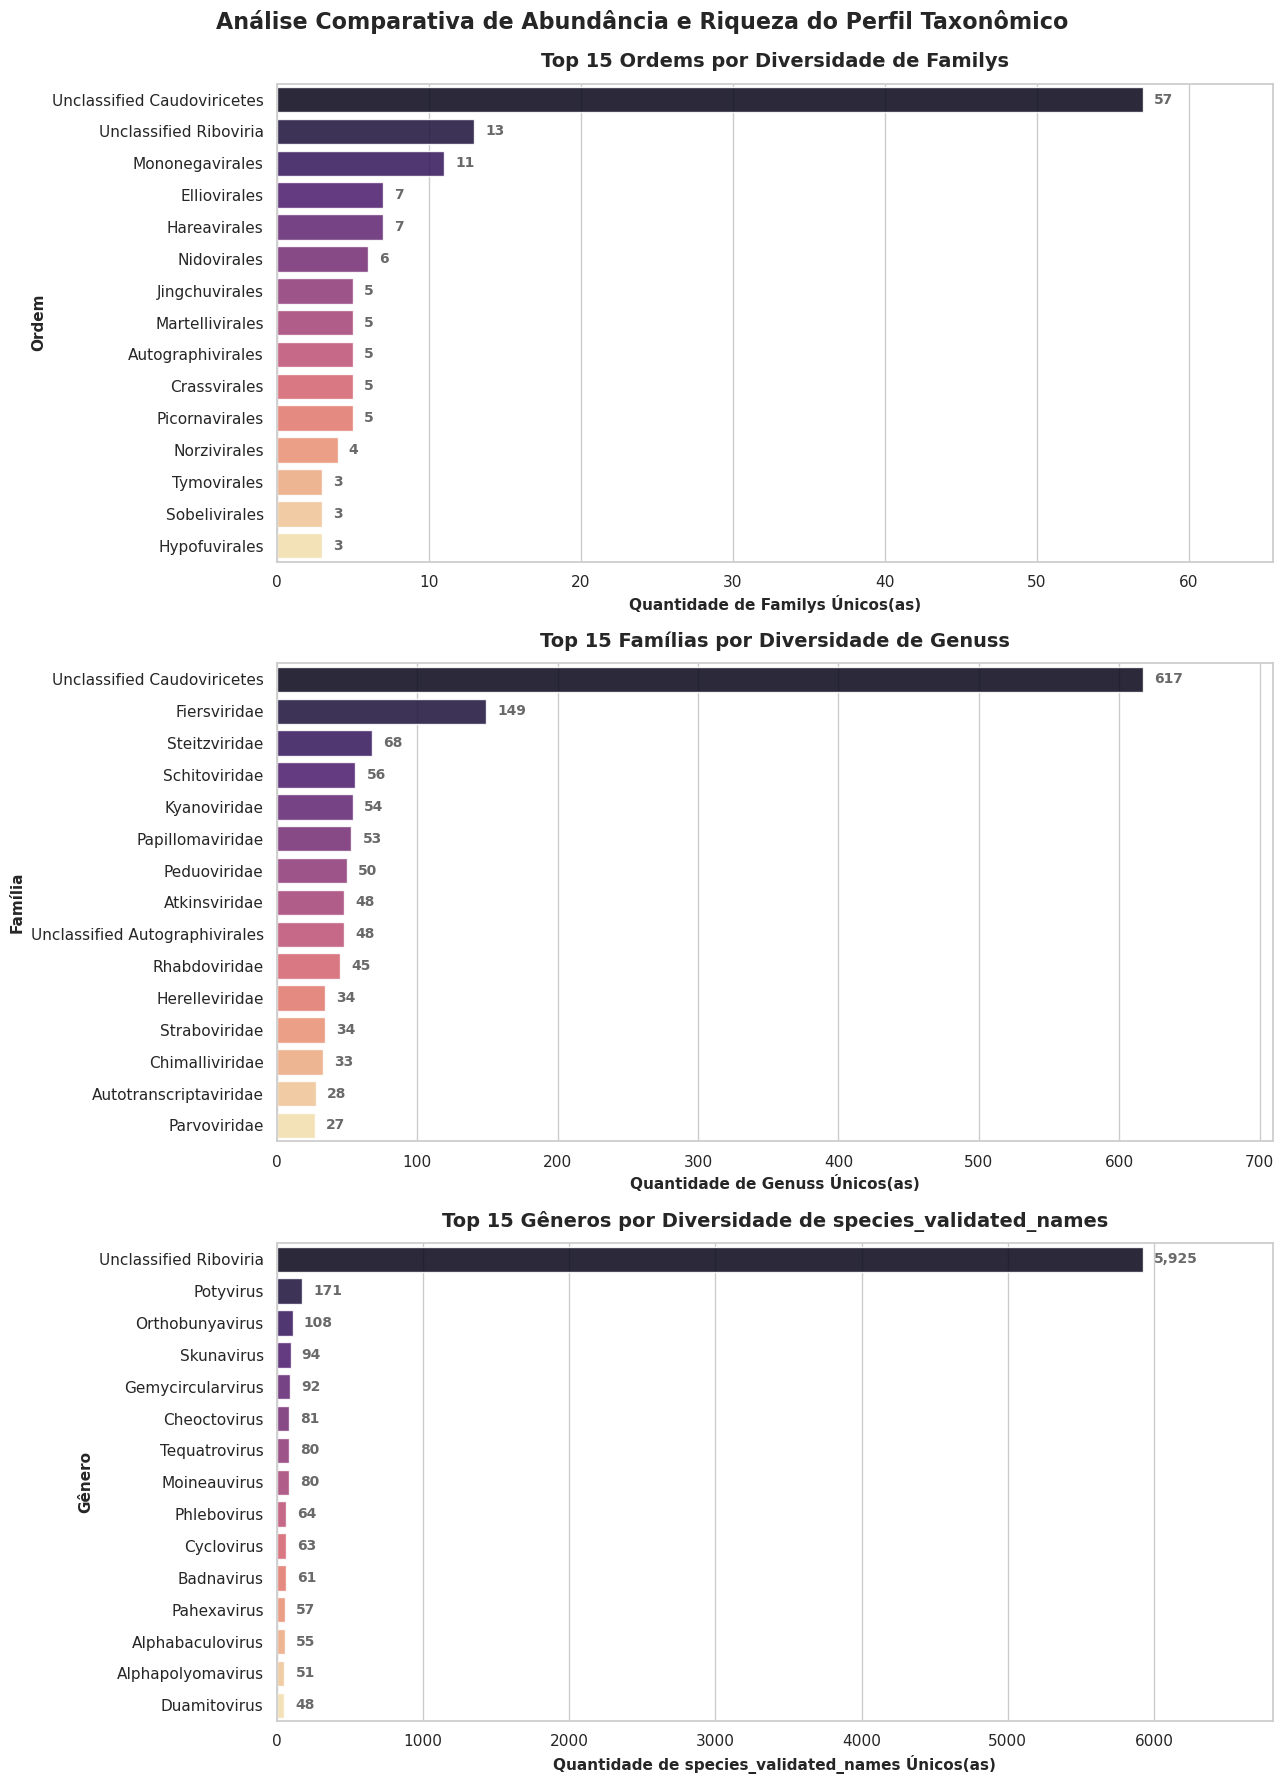

In [10]:
plot_hybrid_taxonomy_frequency(df_final_saneado, top_n=15)

/tmp/ipykernel_1188773/3317711665.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


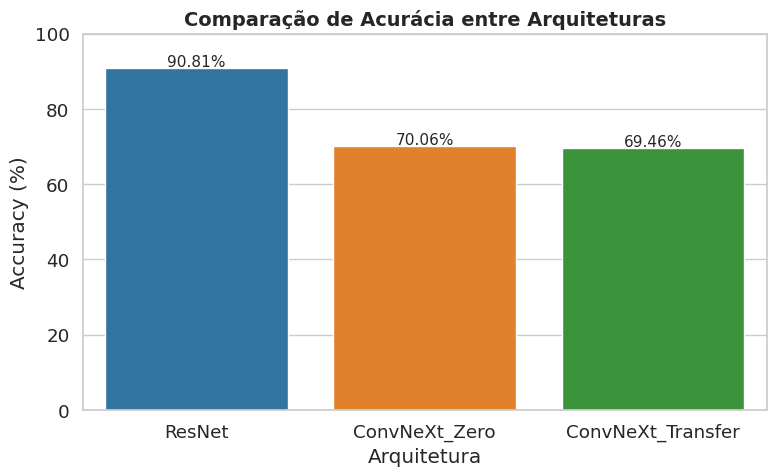

In [11]:
df_plt = pd.DataFrame({
    "names":["ResNet","ConvNeXt_Zero","ConvNeXt_Transfer"],
    "Acc": [90.809147 ,70.055545,69.463323]
})
# Estilo
sns.set(style="whitegrid", font_scale=1.2)

# Figura
plt.figure(figsize=(8, 5))

# Gráfico de barras
ax = sns.barplot(
    data=df_plt,
    x="names",
    y="Acc",
    palette=["#1f77b4", "#ff7f0e", "#2ca02c"]
)

# Adiciona valores nas barras
for i, v in enumerate(df_plt["Acc"]):
    ax.text(i, v + 0.5, f"{v:.2f}%", ha='center', fontsize=11)

# Configurações
plt.title("Comparação de Acurácia entre Arquiteturas", fontsize=14, weight='bold')
plt.xlabel("Arquitetura")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

# Melhor layout
plt.tight_layout()

# Exibe
plt.show()